**Основная гипотеза**

H0: удержание на 7-й день одинаково в обеих группах.

H1: удержание на 7-й день различается между gate_30 и gate_40.

Главная метрика: доля игроков, вернувшихся через 7 дней (retention_7).

**Дополнительная гипотеза**

H0: удержание на 1-й день одинаково в обеих группах.

H1: различается.

Метрика: retention_1.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

df = pd.read_csv("cookie_cats.csv")
print(df.shape)
print(df.head())
print("Пропуски:\n", df.isna().sum())
print("Дубли игроков:", df.userid.duplicated().sum())
print("Уникальных игроков:", df.userid.nunique())
print("Установили, но не играли:", (df.sum_gamerounds == 0).sum())
print("Общее удержание:\n", df[["retention_1", "retention_7"]].mean())

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
Пропуски:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
Дубли игроков: 0
Уникальных игроков: 90189
Установили, но не играли: 3994
Общее удержание:
 retention_1    0.445210
retention_7    0.186065
dtype: float64


Пропусков и дублей нет.

Рассмотрим разделение на группы.

In [ ]:
counts = df["version"].value_counts().sort_index()
print(counts)

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64


**Основная метрика (retention_7)**

In [ ]:
g7 = df.groupby("version")["retention_7"].agg(["sum", "count", "mean"])
print(g7)

z7, p7 = proportions_ztest(g7["sum"], g7["count"])
print(f"retention_7: z = {z7:.3f}, p-value = {p7:.4f}")

low, high = confint_proportions_2indep(
    g7["sum"].iloc[0], g7["count"].iloc[0],
    g7["sum"].iloc[1], g7["count"].iloc[1])
print(f"95% ДИ разности (gate_30 - gate_40): [{low:.4f}, {high:.4f}]")

          sum  count      mean
version                       
gate_30  8502  44700  0.190201
gate_40  8279  45489  0.182000
retention_7: z = 3.164, p-value = 0.0016
95% ДИ разности (gate_30 - gate_40): [0.0031, 0.0133]


При переносе порога на уровень 40 доля пользователей, удержавшихся на седьмой день, снизилась до 18,2 % по сравнению с 19 % в контрольной группе с порогом на уровне 30. Разница не случайна, статистический анализ показывает устойчивый эффект. Версия с порогом 30 даёт дополнительно примерно от 0,3 до 1,3 процентных пункта удержания. В относительном выражении это около 4,5 % прироста к уровню gate 40. Поэтому предпочтительной выглядит версия с порогом 30

**Дополнительная метрика (retention_1)**

In [ ]:
g1 = df.groupby("version")["retention_1"].agg(["sum", "count", "mean"])
print(g1)
z1, p1 = proportions_ztest(g1["sum"], g1["count"])
print(f"z = {z1:.3f}, p-value = {p1:.4f}")

low, high = confint_proportions_2indep(
    g1["sum"].iloc[0], g1["count"].iloc[0],
    g1["sum"].iloc[1], g1["count"].iloc[1])
print(f"95% ДИ разности (gate_30 - gate_40): [{low:.4f}, {high:.4f}]")

           sum  count      mean
version                        
gate_30  20034  44700  0.448188
gate_40  20119  45489  0.442283
z = 1.784, p-value = 0.0744
95% ДИ разности (gate_30 - gate_40): [-0.0006, 0.0124]


По retention‑1 статистически значимых различий между версиями не обнаружено (p = 0.074). Доверительный интервал разности долей удержания (gate_30 − gate_40) включает ноль: [−0.15, +1.33 процентных пункта]. Это означает, что наблюдаемая разница в 0.59 п.п. может быть обусловлена случайной вариацией. По данной метрике ни одна из версий не демонстрирует устойчивого преимущества.

In [ ]:
rng = np.random.default_rng(42)
rows = []
for _ in range(1000):
    s = df.sample(frac=1, replace=True, random_state=int(rng.integers(10**9)))
    m = s.groupby("version")[["retention_1", "retention_7"]].mean()
    rows.append({
        "diff_1": (m.loc["gate_30", "retention_1"] / m.loc["gate_40", "retention_1"] - 1) * 100,
        "diff_7": (m.loc["gate_30", "retention_7"] / m.loc["gate_40", "retention_7"] - 1) * 100,
    })
boot = pd.DataFrame(rows)

print("95% интервал разницы, %:\n", boot.quantile([0.025, 0.975]))
print("P(gate_30 лучше по 1-му дню):", (boot.diff_1 > 0).mean())
print("P(gate_30 лучше по 7-му дню):", (boot.diff_7 > 0).mean())

95% интервал разницы, %:
          diff_1    diff_7
0.025 -0.108110  1.933899
0.975  2.789007  7.444976
P(gate_30 лучше по 1-му дню): 0.962
P(gate_30 лучше по 7-му дню): 1.0


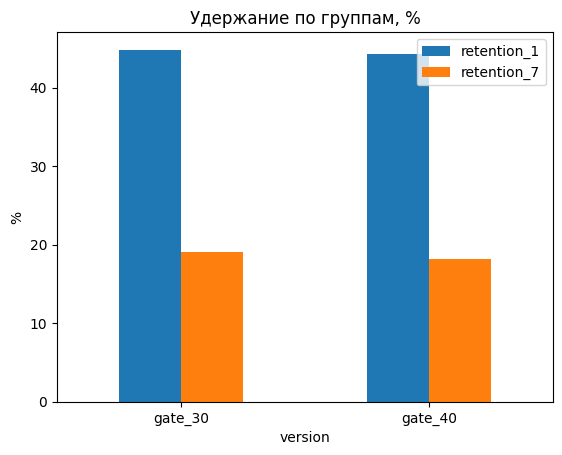

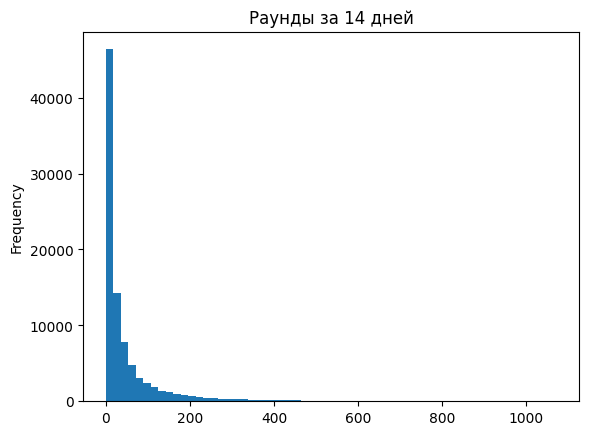

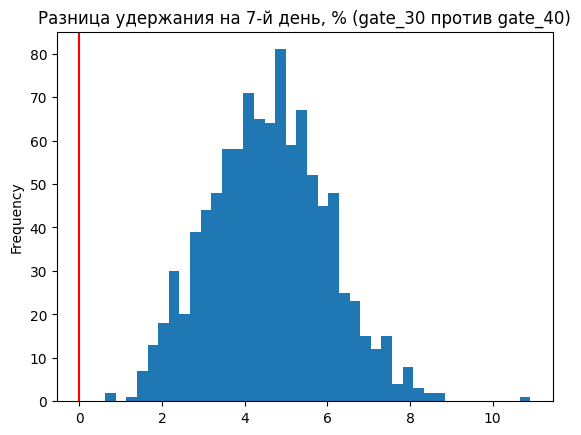

In [ ]:

ret = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
ret.plot(kind="bar", title="Удержание по группам, %")
plt.ylabel("%"); plt.xticks(rotation=0); plt.show()

cut = df.sum_gamerounds.quantile(0.999)
df[df.sum_gamerounds <= cut].sum_gamerounds.plot.hist(bins=60, title="Раунды за 14 дней")
plt.show()

boot.diff_7.plot.hist(bins=40, title="Разница удержания на 7-й день, % (gate_30 против gate_40)")
plt.axvline(0, color="red"); plt.show()

**Результат.** Gate_30 лучше gate_40 по удержанию на 7‑й день: относительный прирост 1.9–7.4% (95% ДИ), вероятность выигрыша — 100%. По 1‑му дню эффект неустойчив: ДИ включает ноль (−0.11–2.79%), хотя в 96.2% симуляций gate_30 выигрывала.

**Рекомендация.** Внедрять gate_30

In [ ]:
import sqlite3
conn = sqlite3.connect("cookie_cats.db")
df.to_sql("players", conn, if_exists="replace", index=False)
conn.close()

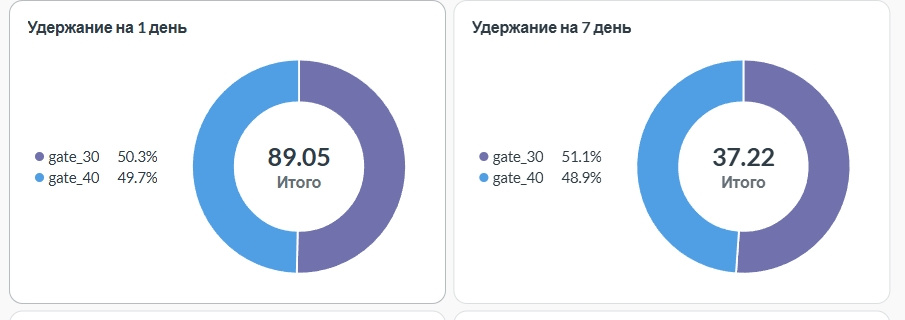

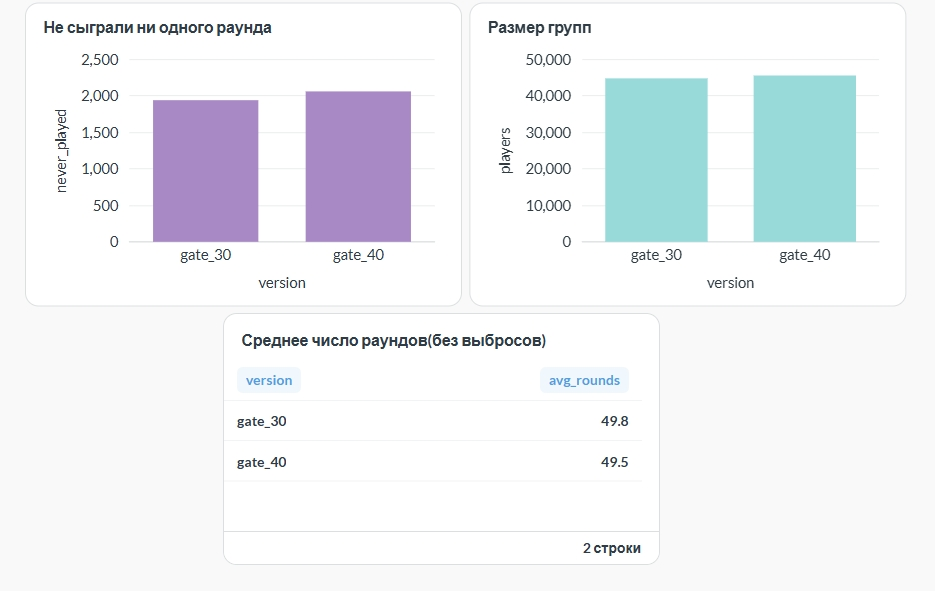